Import del dataset e analisi delle prime 5 righe

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kurtosis, skew

# Impostiamo il formato dei numeri decimali per leggerli meglio
pd.options.display.float_format = '{:.2f}'.format

# Caricamento del dataset 
# (Assicurati che il nome della cartella e del file siano scritti esattamente così)
df = pd.read_csv('Dataset/AB_NYC_2019.csv')

# Riempiamo i valori mancanti nelle recensioni con 0 per evitare errori matematici dopo
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

# Stampiamo le info di base e le prime 5 righe
print(df.info())
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  str    
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     38843 non-n

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.65,-73.97,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75,-73.98,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.81,-73.94,Private room,150,3,0,NaN,0.00,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.69,-73.96,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.80,-73.94,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


Variabili Categoriche

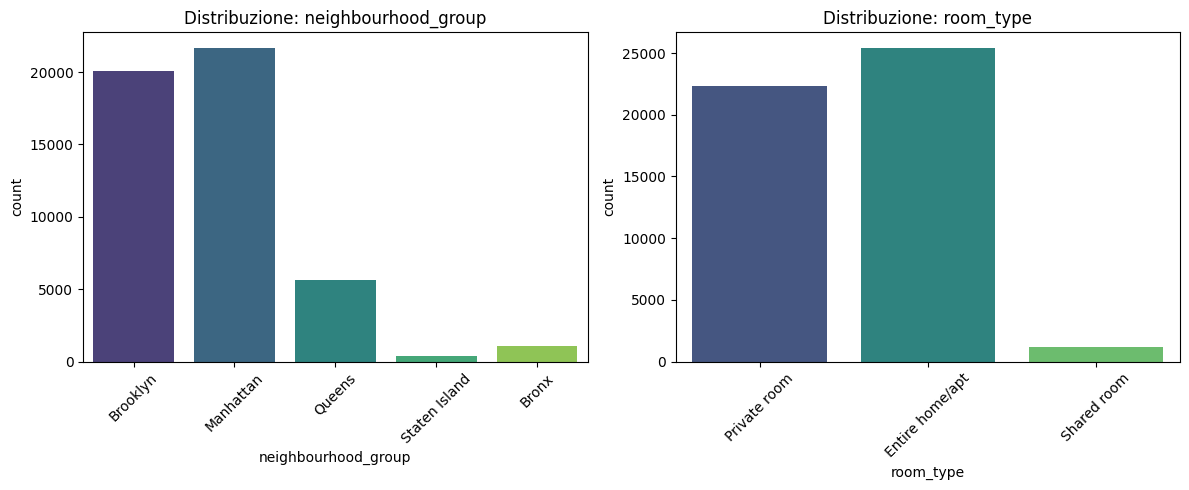

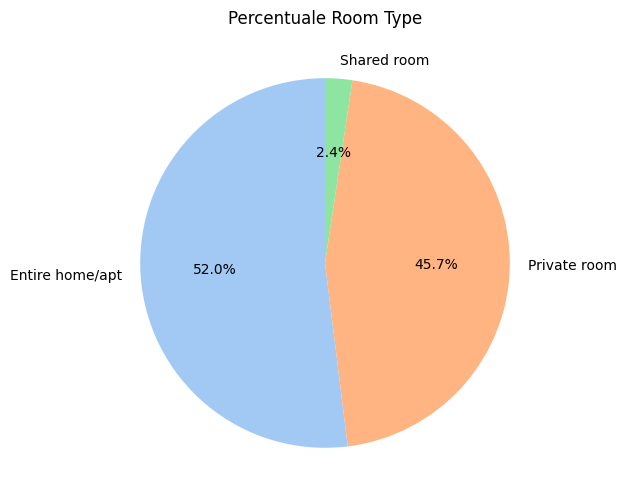

--- Tabelle delle Frequenze ---

Variabile: NEIGHBOURHOOD_GROUP


,Frequenza Assoluta,% Relativa
neighbourhood_group,,
Manhattan,21661,44.3%
Brooklyn,20104,41.12%
Queens,5666,11.59%
Bronx,1091,2.23%
Staten Island,373,0.76%



Variabile: ROOM_TYPE


,Frequenza Assoluta,% Relativa
room_type,,
Entire home/apt,25409,51.97%
Private room,22326,45.66%
Shared room,1160,2.37%


In [3]:
# --- STEP 2: VARIABILI CATEGORICHE ---
cat_vars = ['neighbourhood_group', 'room_type']

# 1. Griglia di Barplots (Countplots per contare le frequenze)
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))
ax = ax.flatten()

for i in range(len(cat_vars)):
    sns.countplot(data=df, x=cat_vars[i], ax=ax[i], palette='viridis', hue=cat_vars[i], legend=False)
    ax[i].set_title(f'Distribuzione: {cat_vars[i]}')
    ax[i].tick_params(axis='x', rotation=45) # Ruotiamo le etichette per leggerle bene

plt.tight_layout()
plt.show()

# 2. Pie Chart (Grafico a torta per i tipi di stanza)
room_counts = df['room_type'].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(room_counts, labels=room_counts.index, autopct='%1.1f%%', startangle=90, colors=sns.color_palette('pastel'))
plt.title('Percentuale Room Type')
plt.show()

# TABELLE DELLE FREQUENZE ---
print("--- Tabelle delle Frequenze ---")

for col in cat_vars:
    print(f"\nVariabile: {col.upper()}")
    
    # Calcoliamo le frequenze assolute (il conteggio)
    freq_assoluta = df[col].value_counts()
    
    # Calcoliamo le frequenze relative (in percentuale)
    freq_relativa = df[col].value_counts(normalize=True) * 100
    
    # Uniamo i risultati in un'unica tabella (DataFrame) bella da vedere
    tabella_frequenze = pd.DataFrame({
        'Frequenza Assoluta': freq_assoluta,
        '% Relativa': freq_relativa
    })
    
    # Aggiungiamo il simbolo % per chiarezza
    tabella_frequenze['% Relativa'] = tabella_frequenze['% Relativa'].round(2).astype(str) + '%'
    
    # Usiamo display() per mostrare la tabella formattata
    display(tabella_frequenze)

Variabili Numeriche

--- Statistiche Descrittive ---


,price,minimum_nights,number_of_reviews,availability_365
count,48895.00,48895.00,48895.00,48895.00
mean,152.72,7.03,23.27,112.78
std,240.15,20.51,44.55,131.62
min,0.00,1.00,0.00,0.00
25%,69.00,1.00,1.00,0.00
50%,106.00,3.00,5.00,45.00
75%,175.00,5.00,24.00,227.00
max,10000.00,1250.00,629.00,365.00



--- Indici di Forma (Skewness e Kurtosis) ---


,Variabile,Kurtosis,Skewness
0,price,585.61,19.12
1,minimum_nights,853.98,21.83
2,number_of_reviews,19.53,3.69
3,availability_365,-1.00,0.76


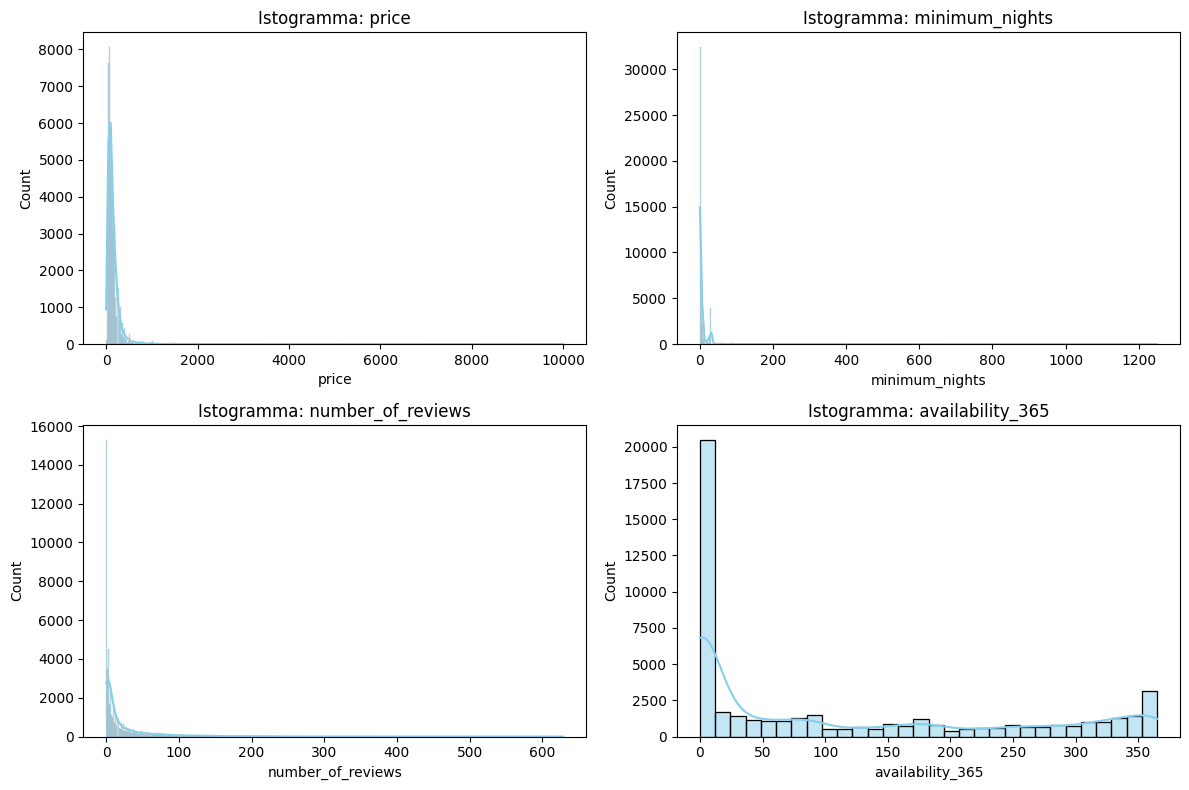

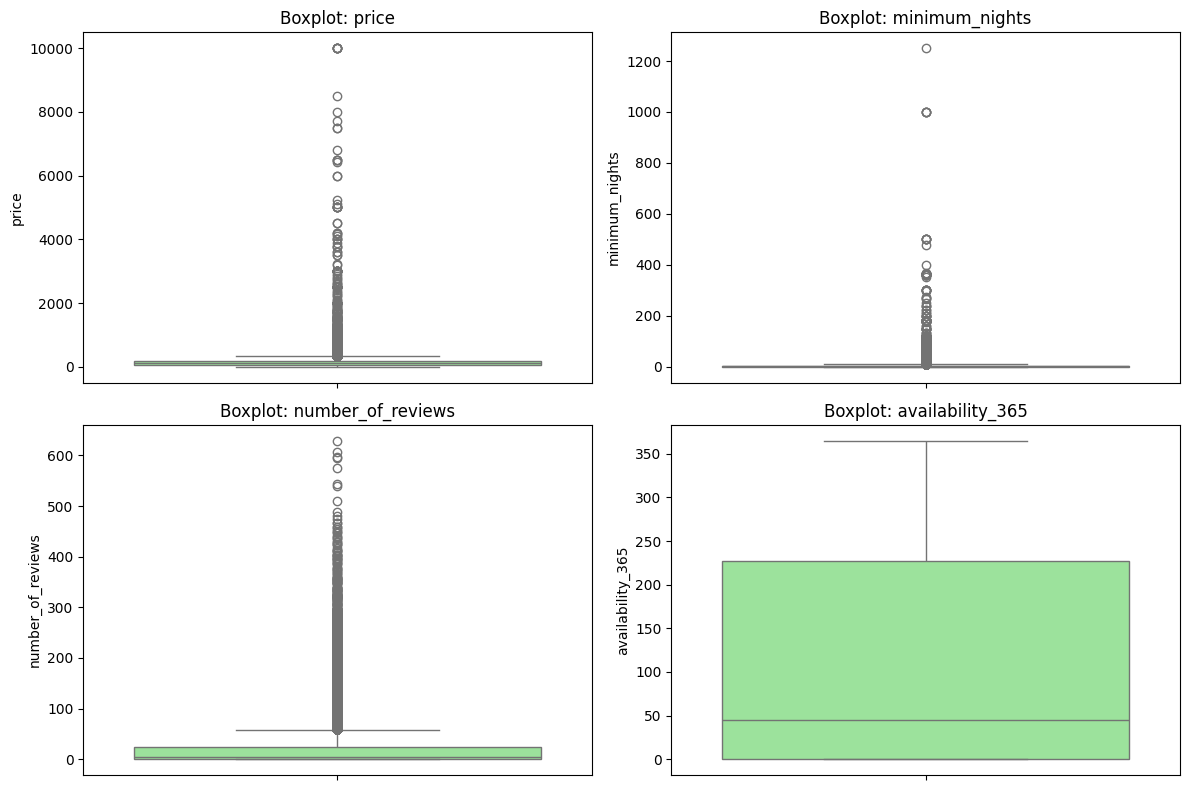

In [4]:
# --- STEP 3: VARIABILI NUMERICHE ---
num_vars = ['price', 'minimum_nights', 'number_of_reviews', 'availability_365']

# 1. Statistiche Descrittive di Base
print("--- Statistiche Descrittive ---")
# Usiamo display() che nei notebook formatta le tabelle molto meglio di print()
display(df[num_vars].describe()) 

# 2. Calcolo di Skewness (Asimmetria) e Kurtosis (Curtosi)
results = []
for n in num_vars:
    # nan_policy='omit' ignora i valori mancanti senza dare errore
    k = kurtosis(df[n], nan_policy='omit') 
    s = skew(df[n], nan_policy='omit')
    results.append({'Variabile': n, 'Kurtosis': k, 'Skewness': s})

df_skew_kurt = pd.DataFrame(results)
print("\n--- Indici di Forma (Skewness e Kurtosis) ---")
display(df_skew_kurt)

# 3. Istogrammi con curva di densità (KDE)
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(12, 8))
ax = ax.flatten()

for i in range(len(num_vars)):
    sns.histplot(data=df, x=num_vars[i], kde=True, ax=ax[i], color='skyblue')
    ax[i].set_title(f'Istogramma: {num_vars[i]}')

plt.tight_layout()
plt.show()

# 4. Boxplots per visualizzare gli Outliers (valori anomali)
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(12, 8))
ax = ax.flatten()

for i in range(len(num_vars)):
    sns.boxplot(data=df, y=num_vars[i], ax=ax[i], color='lightgreen')
    ax[i].set_title(f'Boxplot: {num_vars[i]}')

plt.tight_layout()
plt.show()

Analisi Bivariata e Multivariata

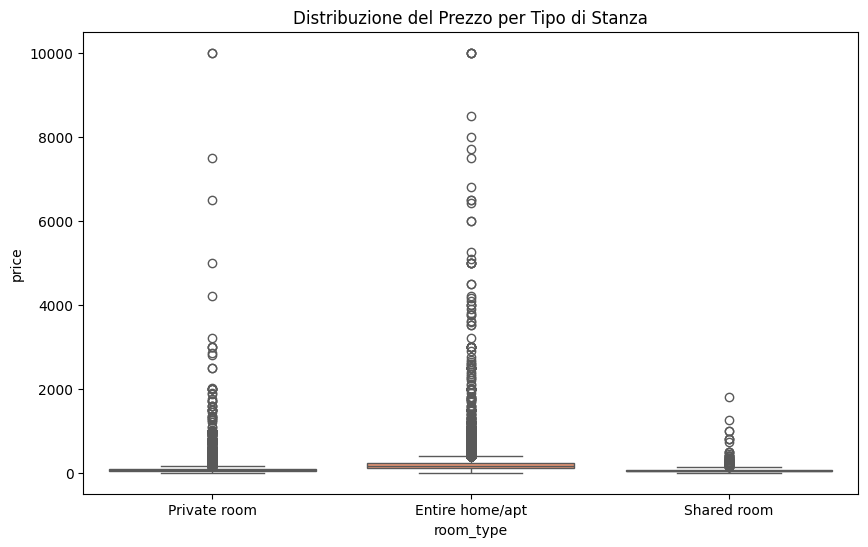

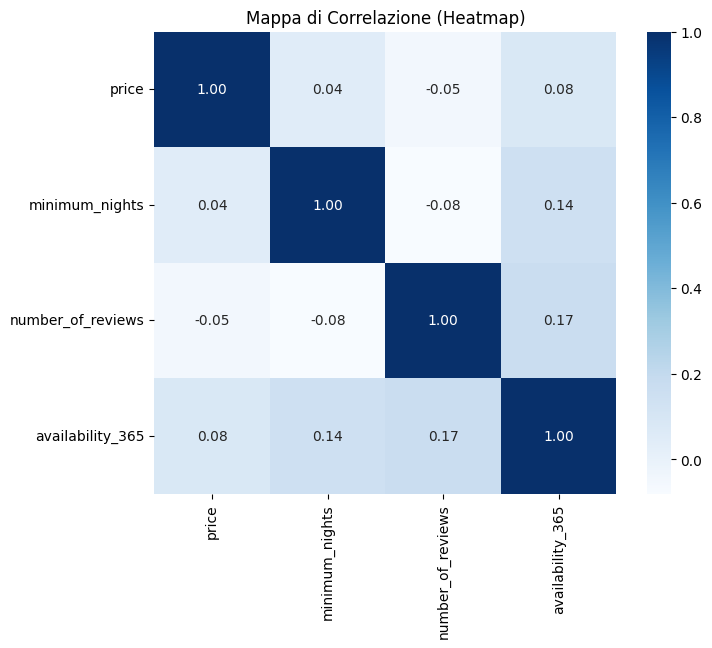

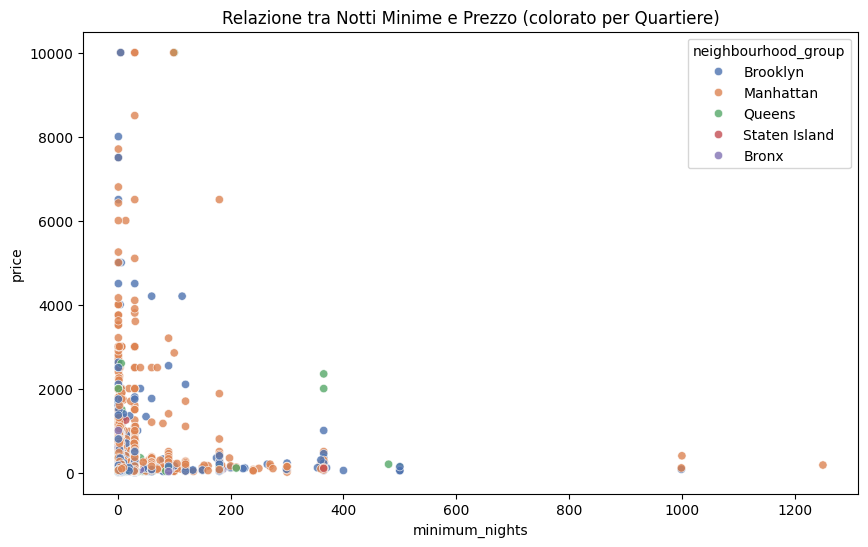

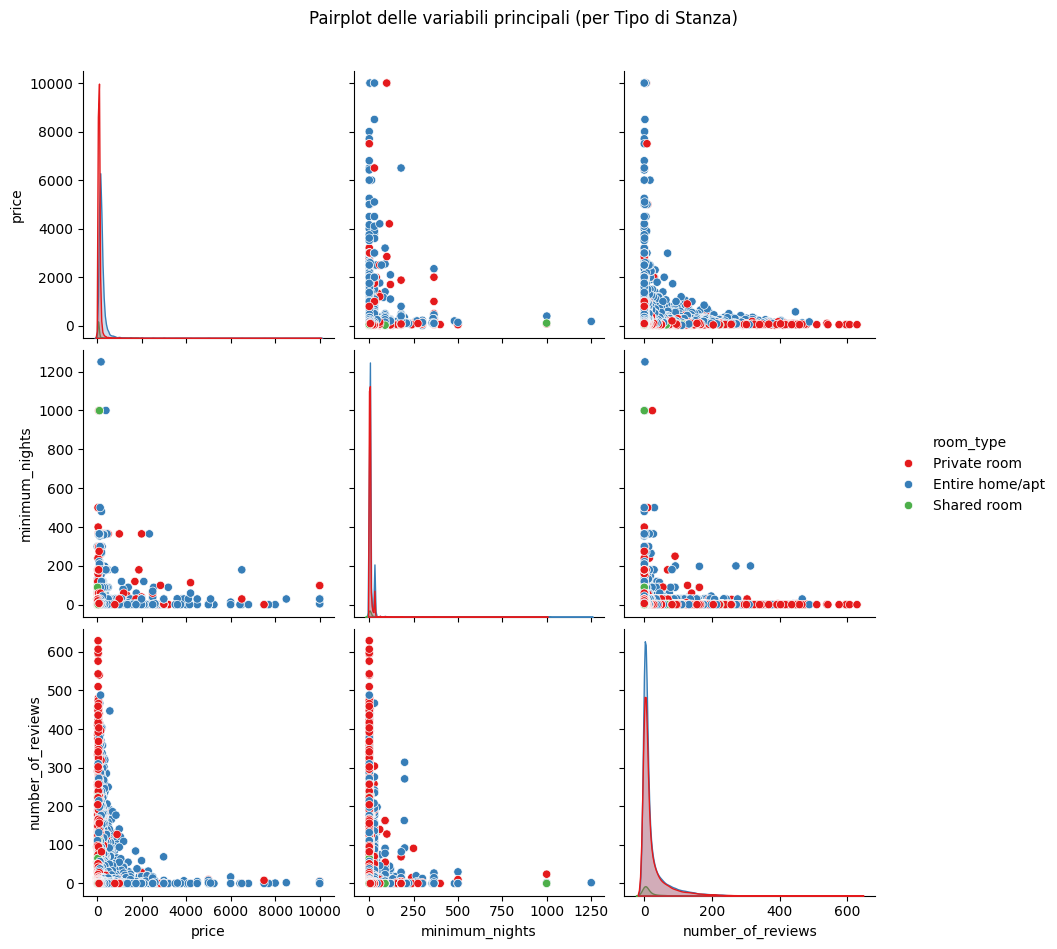

--- Matrice di Covarianza ---


,price,minimum_nights,number_of_reviews,availability_365
price,57674.03,210.82,-513.06,2586.58
minimum_nights,210.82,420.68,-73.21,389.57
number_of_reviews,-513.06,-73.21,1984.75,1008.74
availability_365,2586.58,389.57,1008.74,17324.43


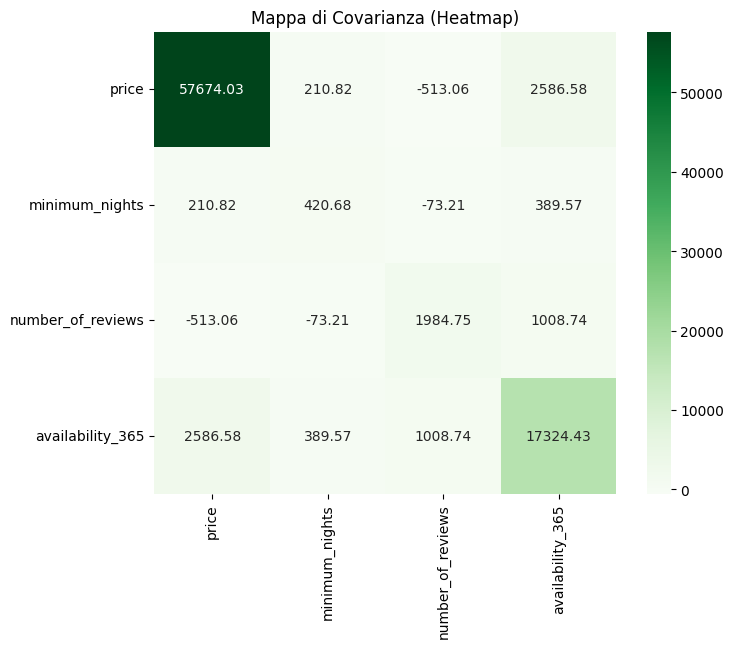

In [7]:
# --- STEP 4: ANALISI BIVARIATA E MULTIVARIATA ---

# 1. Boxplot incrociato (Variabile Numerica + Variabile Categorica)
# Vediamo come cambia il prezzo in base al tipo di stanza
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="room_type", y="price", hue="room_type", palette='Set2')
plt.title('Distribuzione del Prezzo per Tipo di Stanza')
plt.show()

# 2. Matrice di Correlazione e Heatmap (Solo su variabili numeriche)
# Calcola quanto due variabili "si muovono insieme" (da -1 a 1)
corrmat = df[num_vars].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corrmat, cmap="Blues", annot=True, fmt=".2f", square=True)
plt.title('Mappa di Correlazione (Heatmap)')
plt.show()

# 3. Scatterplot (Relazione tra 2 variabili continue colorate per categoria)
# Mettiamo a confronto le Notti Minime e il Prezzo, colorando i punti per Quartiere
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='minimum_nights', y='price', hue='neighbourhood_group', alpha=0.8, palette='deep')
plt.title('Relazione tra Notti Minime e Prezzo (colorato per Quartiere)')
plt.show()

# 4. Pairplot (La panoramica globale)
# Crea una griglia automatica che incrocia tutte le variabili principali
sns.pairplot(df, vars=['price', 'minimum_nights', 'number_of_reviews'], hue="room_type", height=3, palette='Set1')
plt.suptitle('Pairplot delle variabili principali (per Tipo di Stanza)', y=1.05)
plt.show()


# 2.5 Matrice di Covarianza
# Calcola la variabilità congiunta (non è standardizzata tra -1 e 1 come la correlazione)
covmat = df[num_vars].cov()

print("--- Matrice di Covarianza ---")
display(covmat)

# Se vuoi anche disegnarla come Heatmap (opzionale, ma fa molta scena):
plt.figure(figsize=(8, 6))
sns.heatmap(covmat, cmap="Greens", annot=True, fmt=".2f", square=True)
plt.title('Mappa di Covarianza (Heatmap)')
plt.show()

Histogram Bins e Hex Bin Plot

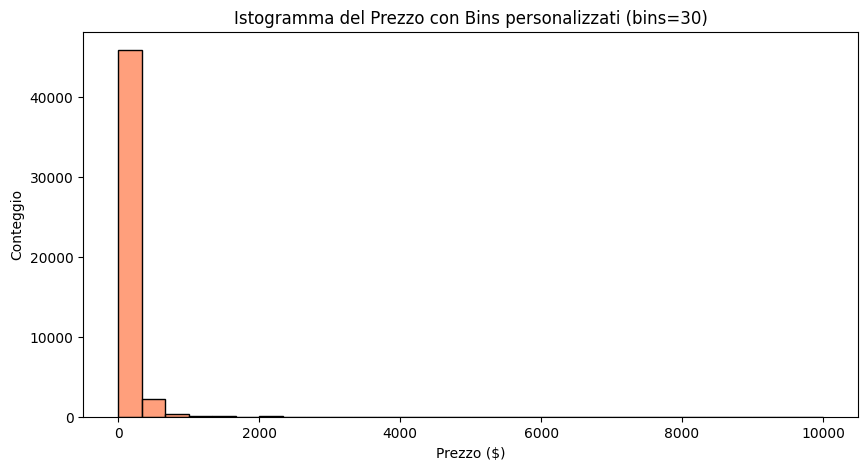

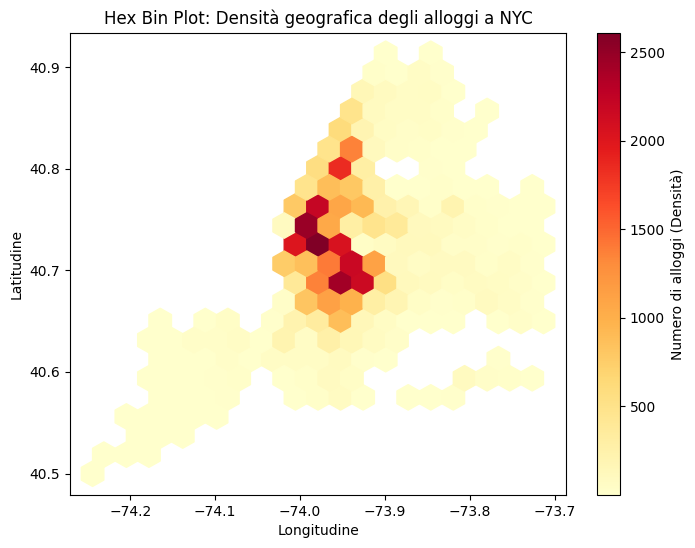

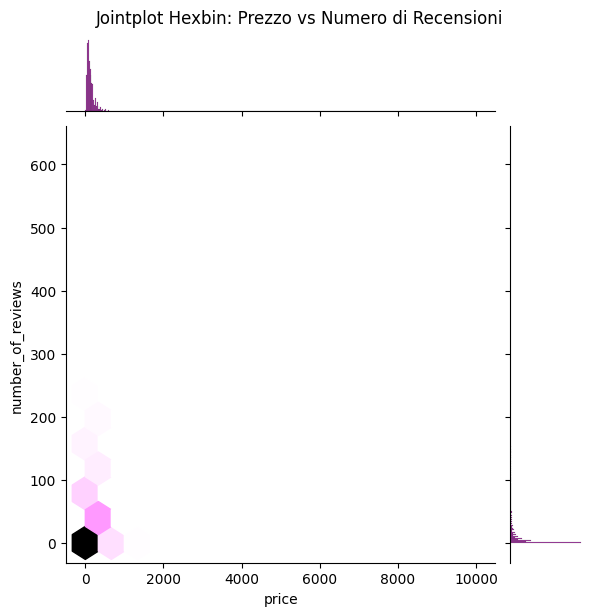

In [6]:
# --- APPROFONDIMENTO: BINS E HEXBIN PLOT ---

# 1. Giocare con i Bins dell'Istogramma (Focus sul Prezzo)
plt.figure(figsize=(10, 5))
# Forziamo l'istogramma a usare 30 "cestini" (bins) invece di quelli standard
sns.histplot(data=df, x='price', bins=30, kde=False, color='coral')
plt.title('Istogramma del Prezzo con Bins personalizzati (bins=30)')
plt.xlabel('Prezzo ($)')
plt.ylabel('Conteggio')
plt.show()

# 2. Hex Bin Plot (Densità geografica degli alloggi)
plt.figure(figsize=(8, 6))
# Usiamo latitudine e longitudine per creare una mappa di densità!
# gridsize indica quanto devono essere piccoli gli esagoni (più è alto, più sono piccoli)
plt.hexbin(x=df['longitude'], y=df['latitude'], gridsize=20, cmap='YlOrRd', mincnt=1)
plt.colorbar(label='Numero di alloggi (Densità)')
plt.title('Hex Bin Plot: Densità geografica degli alloggi a NYC')
plt.xlabel('Longitudine')
plt.ylabel('Latitudine')
plt.show()

# 3. Hex Bin Plot Alternativo (Prezzo vs Recensioni)
# Ottimo per vedere dove si concentra il "grosso" dei dati quando ci sono tante sovrapposizioni
sns.jointplot(data=df, x='price', y='number_of_reviews', kind='hex', color='purple', gridsize=15)
plt.suptitle('Jointplot Hexbin: Prezzo vs Numero di Recensioni', y=1.02)
plt.show()